------- NEW COV ----------
/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/cov/cov_LSST_SRD_area1.800000e+04_ng2.700000e+01_nl4.800000e+01
------- NEW COV ----------
1755 1755
Covariance assembly complete - all covparallel files present
(1755, 1755) (1755, 1755)
min+max eigenvalues full cor:
0.0008958699896573453 79.08928997612686
neg eigenvalues full cor:
min+max eigenvalues 3x2 cov:
2.4066595775183756e-24 1.2608432530346176e-10


/Users/timeifler/anaconda2/lib/python2.7/site-packages/ipykernel_launcher.py:85: RuntimeWarning: divide by zero encountered in log10


------- NEW COV ----------
/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/cov/cov_WFIRST_LSST_area1.800000e+04_ng4.800000e+01_nl5.200000e+01
------- NEW COV ----------
1455 1455
Covariance assembly complete - all covparallel files present
(1455, 1455) (1455, 1455)
min+max eigenvalues full cor:
0.00022243040083465501 117.94319064254022
neg eigenvalues full cor:
min+max eigenvalues 3x2 cov:
7.615562747205743e-25 2.128613883620383e-11
------- NEW COV ----------
/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/cov/cov_WFIRST_std_area2.000000e+03_ng5.100000e+01_nl6.600000e+01
------- NEW COV ----------
1455 1455
Covariance assembly complete - all covparallel files present
(1455, 1455) (1455, 1455)
min+max eigenvalues full cor:
0.00019813840609391348 124.68598324317347
neg eigenvalues full cor:
min+max eigenvalues 3x2 cov:
6.072167019421994e-24 1.9154443756114055e-10


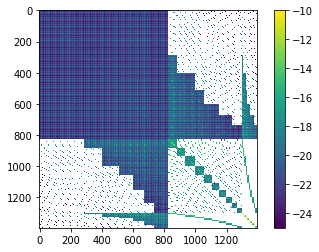

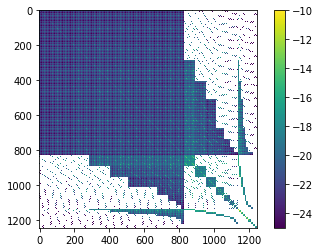

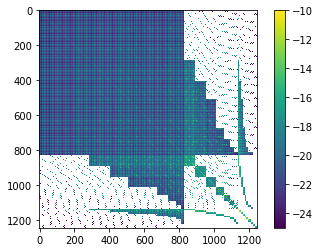

In [2]:
import sys
import os
import math, numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from numpy import linalg as LA
import numpy as np

#infile = os.listdir('/users/timeifler/Dropbox/cosmolike_store/LSST_emu/cov/')
# data = [x[4:29] for x in infile]
# data= [i.replace('LSST_Y10','LSST_3x2pt_Y10') for i in data]
# outname= [i.replace('cov_','') for i in infile]
infile = ["cov_LSST_SRD_area1.800000e+04_ng2.700000e+01_nl4.800000e+01",
          "cov_WFIRST_LSST_area1.800000e+04_ng4.800000e+01_nl5.200000e+01",
          "cov_WFIRST_std_area2.000000e+03_ng5.100000e+01_nl6.600000e+01"]

data= ["3x2pt_LSST_Y10_area=1.800000e+04_dmo","3x2pt_WFIRST_area=1.800000e+04_dmo","3x2pt_WFIRST_area=2.000000e+03_dmo"]
outname= ["3x2pt_LSST_Y10_area=1.800000e+04_dmo","3x2pt_WFIRST_area=1.800000e+04_dmo","3x2pt_WFIRST_area=2.000000e+03_dmo"]

for k in range(0,3):
    print "------- NEW COV ----------"
    print "/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/cov/"+infile[k]
    print "------- NEW COV ----------"
    datafile= np.genfromtxt("datav/"+data[k])
    ndata=datafile.shape[0]
    mask = np.zeros(ndata)
    for i in range(0,datafile.shape[0]):
        if (datafile[i,1] >1.0e-15): 
            mask[i]=1.0

    covfile = np.genfromtxt("/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/cov/"+infile[k])
    cov = np.ones((ndata,ndata))
    
    print ndata,int(np.max(covfile[:,0])+1)

    for i in range(0,covfile.shape[0]):
        cov[int(covfile[i,0]),int(covfile[i,1])] = covfile[i,8]+covfile[i,9]
        cov[int(covfile[i,1]),int(covfile[i,0])] = covfile[i,8]+covfile[i,9]
    
    if 1. in cov[:, :]:
        print "Covariance assembly incomplete - covparallel file(s) missing"
    else:
        print "Covariance assembly complete - all covparallel files present"
    
    numpyfile="/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/npcov/npcov_"+outname[k]
    np.save(numpyfile, cov)
    loadfile="/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/npcov/npcov_"+outname[k]+".npy"
    cov2=np.load(loadfile)
    
    print cov.shape, cov2.shape

    cor = np.zeros((ndata,ndata))
    for i in range(0,ndata):
        for j in range(0,ndata):
            if (cov[i,i]*cov[j,j] >0):
                cor[i,j] = cov[i,j]/math.sqrt(cov[i,i]*cov[j,j])


    a = np.sort(LA.eigvals(cor[:,:]))
    
    print "min+max eigenvalues full cor:"
    print np.min(a), np.max(a)
    print "neg eigenvalues full cor:"
    for i in range(0,a.shape[0]):
        if (a[i]< 0.0): print a[i]

    inv = LA.inv(cov[0:ndata,0:ndata])
    a = np.sort(LA.eigvals(cov[0:ndata,0:ndata]))
    print "min+max eigenvalues 3x2 cov:"
    print np.min(a), np.max(a)
    outfile = "/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/inv/inv_"+outname[k]
    f = open(outfile, "w")
    for i in range(0,ndata):
        inv[i,i]=inv[i,i]*mask[i]
        for j in range(0,ndata):
            f.write("%d %d %e\n" %(i,j, inv[i,j]))
    f.close()
    
    maskindices=np.where(mask == 0)[0]
    covnew=np.delete(cov, maskindices, 0)
    covcut=np.delete(covnew, maskindices, 1)
    covzero=np.where(covcut == 0)[0]

    plt.figure()
    plt.imshow(np.log10(np.abs(covcut[:,:])), interpolation="nearest",vmin=-25, vmax=-10)
    plt.colorbar()
    savefile="/users/timeifler/Dropbox/cosmolike_store/WFIRST_LSST/plots/covcut_"+outname[k]+".png"
    plt.savefig(savefile, format='png', dpi=2000)

(1800, 1800) (1725, 1725)
